# 5 — Extract Defect Region Features

## Objective
Generate labelled training examples from RGB images
using COCO annotations as ground truth.

## Methodology
1. Load training images and COCO annotations.
2. Divide images into fixed-size patches.
3. Determine whether patches contain annotated defects.
4. Extract RGB statistics from each patch.
5. Save labelled examples for subsequent model training.

## Inputs
- Training RGB images
- Training COCO annotations

## Outputs
- CSV containing numerical features and defect labels

## Notes
No machine learning model is trained in this notebook.

Only the existing training dataset is used.
Validation images and their annotations remain separate.

## Setup and extraction settings

Define training paths and the 32-pixel patch size. Explicit calls use `PATCH_SIZE`; the helper’s preserved default is 64 pixels.

In [ ]:
# Standard library imports
import json
from pathlib import Path

# Numerical and tabular data processing
import numpy as np
import pandas as pd

# Image loading and visualisation
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Reproducibility settings
RANDOM_SEED = 67

# Directory containing the training images
TRAIN_DIR = Path("../data/cleaned/train")

# COCO annotation file for the training dataset
COCO_PATH = TRAIN_DIR / "_annotations.coco.json"

# File for saving the extracted training examples
OUTPUT_PATH = Path("../data/processed/region_features.csv")

# Initial patch dimensions, in pixels
PATCH_SIZE = 32

## Inspect COCO Annotation Structure

This section examines the structure of the COCO annotation file
associated with the training images.

The objective is to determine how defects are represented,
including their categories, locations, and geometric annotations.

Only training annotations are loaded to ensure that validation
ground truth remains separate from feature extraction.

In [2]:
# Load the COCO annotation file for the training dataset.
# The file contains information about images, defect categories,
# and the locations of annotated defects.

with open(COCO_PATH, "r") as file:
    coco_data = json.load(file)



## Visualise Ground-Truth Defect Locations

This section overlays COCO bounding boxes onto their corresponding
RGB training images.

The purpose is to verify that the annotations correctly identify
defective regions before using them to generate labelled training patches.

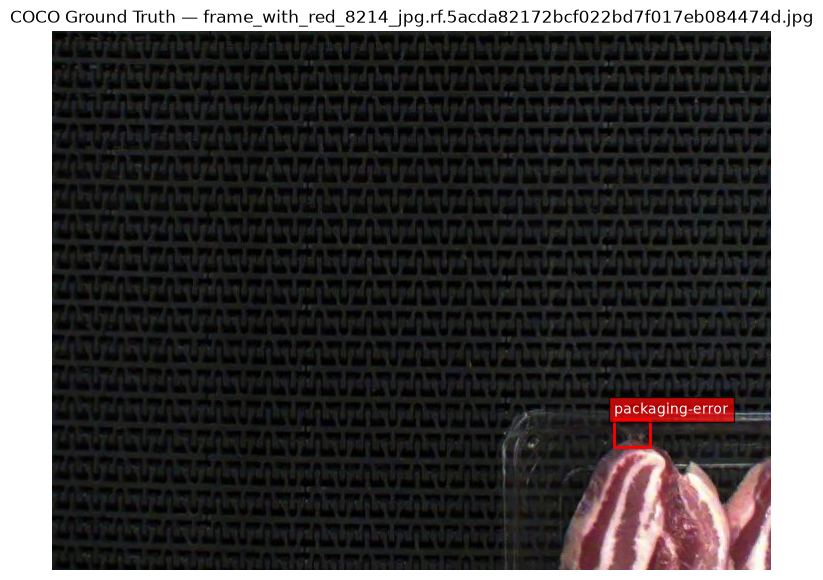

In [3]:
# Select the first image containing an annotation.
example_annotation = coco_data["annotations"][0]

# Find the image ID associated with this annotation.
image_id = example_annotation["image_id"]

# Find the corresponding image information in the COCO dataset.
image_info = next(
    image for image in coco_data["images"]
    if image["id"] == image_id
)

# Construct the path to the image using its COCO filename.
image_path = TRAIN_DIR / image_info["file_name"]

# Load the image and convert it to RGB format.
image = Image.open(image_path).convert("RGB")

# Retrieve all annotations associated with this image.
image_annotations = [
    annotation for annotation in coco_data["annotations"]
    if annotation["image_id"] == image_id
]

# Create the figure and display the original RGB image.
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Draw a bounding box around every annotated defect.
for annotation in image_annotations:

    # COCO bounding boxes use the format [x, y, width, height].
    x, y, width, height = annotation["bbox"]

    # Create a rectangle representing the defect location.
    rectangle = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    # Add the bounding box to the displayed image.
    ax.add_patch(rectangle)

    # Display the defect category above its bounding box.
    category_id = annotation["category_id"]

    category_name = next(
        category["name"]
        for category in coco_data["categories"]
        if category["id"] == category_id
    )

    ax.text(
        x,
        y - 5,
        category_name,
        color="white",
        fontsize=10,
        bbox=dict(facecolor="red", alpha=0.7)
    )

# Add descriptive information to the visualisation.
ax.set_title(f"COCO Ground Truth — {image_info['file_name']}")
ax.axis("off")

plt.show()

## Divide Images into Patches

This section divides an RGB training image into fixed-size
patches for supervised defect detection.

Each patch will become an individual training example.

COCO bounding boxes will subsequently be used to assign
defect, normal, or ambiguous labels to the patches.

The annotations are used only as ground-truth labels;
the predictor features will be extracted from RGB pixels.

In [4]:
# Make the project package importable when running from notebooks/.
import sys
from pathlib import Path

_SRC_PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src" / "__init__.py").is_file()
)
if str(_SRC_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_SRC_PROJECT_ROOT))

from src.patch_processing import extract_training_patches as extract_patches


In [5]:
# Extract patches.
image_patches = extract_patches(image, patch_size=PATCH_SIZE)

# Display the number of extracted patches.
print("Total patches:", len(image_patches))

# Verify the total area covered by the patches.
total_patch_area = sum(
    patch["width"] * patch["height"]
    for patch in image_patches
)

image_area = image.width * image.height

print("Image area:", image_area)
print("Patch coverage:", total_patch_area / image_area * 100, "%")

Total patches: 391
Image area: 388800
Patch coverage: 100.0 %


## Measure bounding-box overlap

Calculate the fraction of a patch covered by a bounding box. This supports the normal, ambiguous and defect label rules.

In [6]:
from src.patch_processing import calculate_patch_overlap


## Assign Ground-Truth Labels to Patches

This section assigns a training label to each extracted patch
using overlap with the COCO defect bounding boxes.

Patch labels:
- 1  = defect
- 0  = normal
- -1 = ambiguous

The ambiguous class is used for patches with only small
partial overlap, which may not clearly represent either
a defect or a normal region.

In [7]:
from src.patch_processing import label_patch


In [8]:
# Extract 32 x 32 patches from the current example image.
image_patches = extract_patches(image, patch_size=PATCH_SIZE)

# Label every patch using the COCO annotations.
labelled_patches = []

for patch in image_patches:
    label, max_overlap, matched_category_id = label_patch(
        patch,
        image_annotations,
        defect_threshold=0.20
    )

    labelled_patches.append({
        "x": patch["x"],
        "y": patch["y"],
        "width": patch["width"],
        "height": patch["height"],
        "label": label,
        "max_overlap": max_overlap,
        "category_id": matched_category_id
    })

# Convert results to a dataframe for easy inspection.
labelled_patches_df = pd.DataFrame(labelled_patches)

# Display the first few labelled patches.
labelled_patches_df.head()

,x,y,width,height,label,max_overlap,category_id
0,0,0,32,32,0,0.0,NaN
1,32,0,32,32,0,0.0,NaN
2,64,0,32,32,0,0.0,NaN
3,96,0,32,32,0,0.0,NaN
4,128,0,32,32,0,0.0,NaN


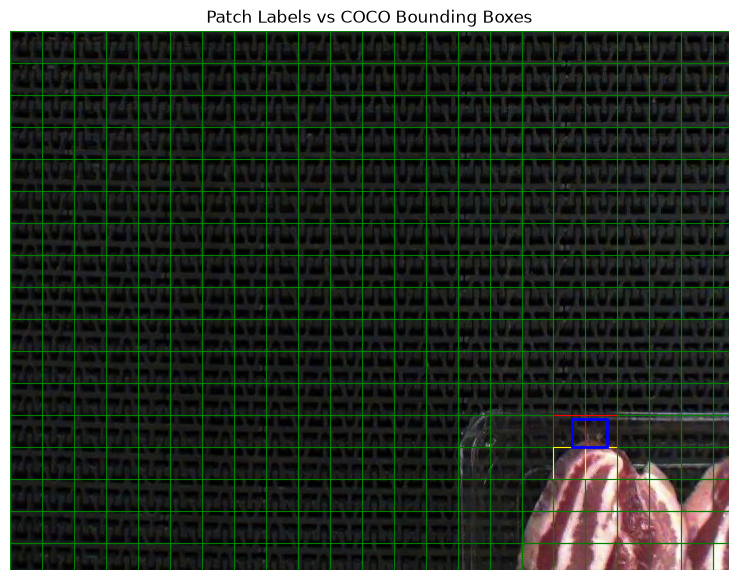

In [9]:
# Display the image.
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(image)

# Colour patches according to their assigned label.
for _, row in labelled_patches_df.iterrows():

    if row["label"] == 1:
        edge_colour = "red"       # defect
    elif row["label"] == 0:
        edge_colour = "green"     # normal
    else:
        edge_colour = "yellow"    # ambiguous

    rectangle = patches.Rectangle(
        (row["x"], row["y"]),
        row["width"],
        row["height"],
        linewidth=0.8,
        edgecolor=edge_colour,
        facecolor="none"
    )

    ax.add_patch(rectangle)

# Add the original COCO annotations in blue for comparison.
for annotation in image_annotations:
    x, y, width, height = annotation["bbox"]

    rectangle = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=2,
        edgecolor="blue",
        facecolor="none"
    )

    ax.add_patch(rectangle)

ax.set_title("Patch Labels vs COCO Bounding Boxes")
ax.axis("off")
plt.show()

In [10]:
# Select patches identified as containing defects.
defect_patches = labelled_patches_df[
    labelled_patches_df["label"] == 1
]

# Display their coordinates, overlap ratios and defect categories.
print("Number of defect patches:", len(defect_patches))

display(defect_patches.head(10))

Number of defect patches: 2


,x,y,width,height,label,max_overlap,category_id
293,544,384,32,32,1,0.379757,2.0
294,576,384,32,32,1,0.600226,2.0


In [11]:
# Count patches belonging to each classification.
label_counts = labelled_patches_df["label"].value_counts()

# Include every possible label, even if no patches belong to it.
label_counts = label_counts.reindex([-1, 0, 1], fill_value=0)

# Display descriptive labels alongside the counts.
label_counts.index = ["AMBIGUOUS", "NORMAL", "DEFECT"]

print(label_counts.to_string())

AMBIGUOUS      2
NORMAL       387
DEFECT         2


## Extract RGB Features

This section extracts numerical RGB features from each image patch.

Six features are calculated:
- Mean red, green and blue intensity.
- Standard deviation of red, green and blue intensity.

These features describe the average colour and colour variation
within each patch.

COCO annotations are used to assign ground-truth labels but are
not used to calculate the RGB features.

Ambiguous patches are excluded from the training dataset.

In [12]:
from src.feature_extraction import extract_region_rgb_features as extract_rgb_features


## Generate Labelled Training Dataset

This section processes all RGB images in the training dataset.

Each image is divided into patches, which are labelled using
their overlap with COCO bounding boxes.

RGB features are calculated for all non-ambiguous patches.

The resulting dataset will be exported for use in Notebook 06,
where a supervised region classifier will be trained.

Only the training dataset is processed. Validation images and
annotations remain separate.

In [13]:
from collections import defaultdict

# Create a lookup table associating each image ID with its annotations.
# This is more efficient than searching the entire annotation list
# separately for every image.
annotations_by_image = defaultdict(list)

for annotation in coco_data["annotations"]:
    annotations_by_image[annotation["image_id"]].append(annotation)


# Initialise a list to store the extracted feature records.
feature_records = []

# Track how many ambiguous patches are excluded.
ambiguous_count = 0

# Process every image recorded in the training COCO dataset.
for image_info in coco_data["images"]:

    # Extract the image identifier and filename.
    image_id = image_info["id"]
    filename = image_info["file_name"]

    # Construct the image path.
    image_path = TRAIN_DIR / filename

    # Load the image in RGB format.
    with Image.open(image_path) as img:
        current_image = img.convert("RGB")

    # Divide the image into 32 x 32-pixel patches.
    image_patches = extract_patches(
        current_image,
        patch_size=PATCH_SIZE
    )

    # Retrieve the annotations belonging to this image.
    image_annotations = annotations_by_image[image_id]

    # Process each patch individually.
    for patch in image_patches:

        # Determine whether the patch contains an annotated defect.
        label, max_overlap, category_id = label_patch(
            patch,
            image_annotations,
            defect_threshold=0.20
        )

        # Exclude patches with uncertain ground-truth labels.
        if label == -1:
            ambiguous_count += 1
            continue

        # Calculate RGB statistics from the patch's pixel values.
        rgb_features = extract_rgb_features(patch["rgb"])

        # Store the patch's features and its ground-truth label.
        feature_records.append({
            "image_id": image_id,
            "filename": filename,
            "x": patch["x"],
            "y": patch["y"],
            "width": patch["width"],
            "height": patch["height"],
            **rgb_features,
            "label": label
        })


# Convert the extracted records into a DataFrame.
region_features_df = pd.DataFrame(feature_records)

print("Feature extraction complete.")
print("Total labelled patches:", len(region_features_df))
print("Ambiguous patches excluded:", ambiguous_count)

display(region_features_df.head())

Feature extraction complete.
Total labelled patches: 1300762
Ambiguous patches excluded: 7915


,image_id,filename,x,y,width,height,mean_r,mean_g,mean_b,std_r,std_g,std_b,label
0,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,0,0,32,32,20.934570,22.108398,21.138672,11.025300,11.159137,11.793400,0
1,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,32,0,32,32,22.056641,22.954102,22.741211,12.000843,12.616676,13.242274,0
2,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,64,0,32,32,24.300781,24.996094,23.770508,10.758053,11.645143,12.337976,0
3,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,96,0,32,32,21.693359,23.418945,22.337891,11.463244,11.984743,11.413700,0
4,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,128,0,32,32,21.645508,23.134766,20.901367,11.060837,11.741328,11.364480,0


## Check extracted feature quality and coverage

Inspect patch class balance, missing RGB features and whether annotated images produced at least one positive patch. These are extraction checks, not model performance metrics.

In [14]:
# Count the number of normal and defective training patches.
label_counts = region_features_df["label"].value_counts()

# Display both classes, including any with zero observations.
label_counts = label_counts.reindex([0, 1], fill_value=0)

label_counts.index = ["NORMAL", "DEFECT"]

print("Extracted training examples:")
print(label_counts.to_string())

# Calculate the percentage of defective patches.
defect_percentage = (
    (region_features_df["label"] == 1).mean() * 100
)

print(f"\nDefective patches: {defect_percentage:.2f}%")

Extracted training examples:
NORMAL    1235328
DEFECT      65434

Defective patches: 5.03%


In [15]:
# Define the six numerical features used for training.
RGB_FEATURE_COLUMNS = [
    "mean_r",
    "mean_g",
    "mean_b",
    "std_r",
    "std_g",
    "std_b"
]

# Check whether any feature values are missing.
print(
    region_features_df[RGB_FEATURE_COLUMNS]
    .isna()
    .sum()
)

mean_r    0
mean_g    0
mean_b    0
std_r     0
std_g     0
std_b     0
dtype: int64


In [16]:
# Count how many distinct images contain at least one
# patch labelled as DEFECT.
images_with_defects = region_features_df.loc[
    region_features_df["label"] == 1,
    "image_id"
].nunique()

print("Images containing detected defect patches:",
      images_with_defects)

print("Total training images:",
      len(coco_data["images"]))

Images containing detected defect patches: 2660
Total training images: 3347


In [17]:
# Identify images containing at least one COCO annotation.
annotated_image_ids = {
    annotation["image_id"]
    for annotation in coco_data["annotations"]
}

# Identify images that produced at least one positive patch.
positive_image_ids = set(
    region_features_df.loc[
        region_features_df["label"] == 1,
        "image_id"
    ]
)

# Find annotated images with no positive training patches.
missing_positive_images = (
    annotated_image_ids - positive_image_ids
)

print(
    "Images with COCO annotations:",
    len(annotated_image_ids)
)

print(
    "Annotated images without positive patches:",
    len(missing_positive_images)
)

Images with COCO annotations: 2663
Annotated images without positive patches: 3


## Export Region Features

The labelled training examples are exported to CSV for use
in Notebook 06.

The CSV contains:
- Original image identifiers and patch coordinates.
- Six RGB colour features.
- Ground-truth defect/normal labels.

No machine learning model is trained in this notebook.

The existing train/validation image split remains unchanged.

In [18]:
# Ensure the output directory exists.
OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Export the labelled patch features to a CSV file.
region_features_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(f"Training features saved to: {OUTPUT_PATH}")
print(f"Total rows exported: {len(region_features_df)}")

Training features saved to: ..\data\processed\region_features.csv
Total rows exported: 1300762


### Patch Extraction Evaluation

Using 32 × 32-pixel patches and a minimum bounding-box
overlap threshold of 20%, the feature-extraction procedure
generated positive training patches for 2,662 of the 2,665
images containing COCO defect annotations (99.89%).

Three annotated images did not produce positive patches,
potentially because their annotations were too small or
distributed across patch boundaries.

These results indicate high image-level coverage of
annotated defects, although they do not measure the
performance of a trained defect detector.

The initial threshold of 20% was retained for subsequent
model training and evaluation.